# dbt (data build tool): Beginner to Advanced
**Part of: Building Automated Data Pipelines with Spark, dbt and Airflow**

dbt is the **T in ELT**. You write `SELECT` statements; dbt turns them into tables/views in your warehouse, works out the run order, tests the results and generates documentation.

This notebook uses **dbt-duckdb** (an embedded database, no server to install), so every cell runs on your laptop. The same project works on Snowflake, BigQuery, Postgres, Databricks/Spark and others by changing `profiles.yml`.

| Level | You will learn |
|---|---|
| 🟢 Beginner | Project layout, profiles, seeds, first model, `dbt run`, `ref()` |
| 🟡 Intermediate | Sources, staging/marts layering, tests, docs, materializations |
| 🔴 Advanced | Incremental models, snapshots (SCD2), Jinja & macros, custom tests, selectors, `dbt build`, CI & orchestration |

In [ ]:
%pip install -q "dbt-core>=1.10.5" dbt-duckdb pandas duckdb

## 0. Helper: run shell commands and show output

In [ ]:
import subprocess, textwrap, pathlib, os

def sh(cmd, cwd=None):
    r = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)
    print((r.stdout + r.stderr).strip()[-3500:])
    return r.returncode

def write(path, text):
    p = pathlib.Path(path); p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(textwrap.dedent(text).lstrip("\n"))

def q(sql):
    # Run a query and CLOSE the connection straight away (DuckDB allows one writer at a time).
    import duckdb
    con = duckdb.connect("shop_dbt/shop.duckdb", read_only=True)
    try:
        return con.sql(sql).df()
    finally:
        con.close()

sh("dbt --version")

---
# 🟢 Level 1 - Beginner

## 1.1 Where dbt fits
Data is **extracted and loaded** (by Spark, Airbyte, Fivetran...) into the warehouse. dbt then **transforms** it inside the warehouse in SQL, layer by layer, with tests on every layer.

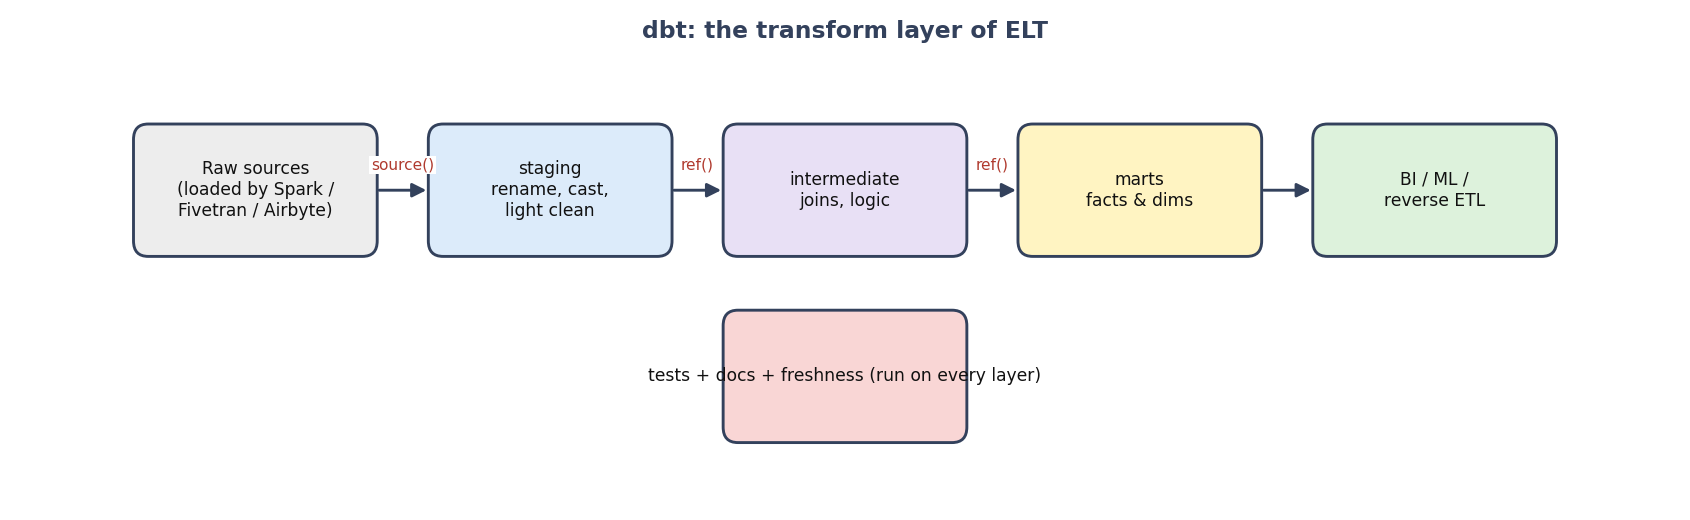

*Raw → staging → intermediate → marts, with tests and docs throughout.*

## 1.2 Create a project
A dbt project is just a folder of text files:

```
shop_dbt/
├── dbt_project.yml      # project config
├── profiles.yml         # connection (kept in project here for the demo)
├── seeds/               # small CSVs loaded as tables
├── models/              # your SELECT statements
├── snapshots/           # SCD2 history
├── macros/              # reusable Jinja
└── tests/               # custom SQL tests
```

In [ ]:
P = "shop_dbt"
write(f"{P}/dbt_project.yml", '''
    name: shop_dbt
    version: "1.0.0"
    profile: shop_dbt
    model-paths: ["models"]
    seed-paths: ["seeds"]
    snapshot-paths: ["snapshots"]
    macro-paths: ["macros"]
    test-paths: ["tests"]
    models:
      shop_dbt:
        staging:
          +materialized: view
        marts:
          +materialized: table
''')

write(f"{P}/profiles.yml", '''
    shop_dbt:
      target: dev
      outputs:
        dev:
          type: duckdb
          path: shop.duckdb
          threads: 4
''')
print("project files written")

## 1.3 Seeds: load CSV data
Seeds are small static CSVs (lookup tables, demo data) that dbt loads with `dbt seed`.

In [ ]:
write(f"{P}/seeds/raw_customers.csv", '''
    customer_id,name,city,tier
    1,Asha,Boston,bronze
    2,Ben,Austin,silver
    3,Chen,Seattle,gold
    4,Dara,Miami,bronze
''')
write(f"{P}/seeds/raw_orders.csv", '''
    order_id,customer_id,order_date,status,amount
    101,1,2026-01-05,completed,120.50
    102,2,2026-01-06,completed,60.00
    103,1,2026-01-09,returned,80.00
    104,3,2026-02-01,completed,400.00
    105,2,2026-02-03,completed,95.25
    106,4,2026-02-10,pending,50.00
''')
sh("dbt seed --profiles-dir .", cwd=P)

## 1.4 Your first model
A model is a `.sql` file containing one `SELECT`. The file name becomes the table/view name.

In [ ]:
write(f"{P}/models/staging/stg_orders.sql", '''
    select
        order_id,
        customer_id,
        cast(order_date as date) as order_date,
        status,
        cast(amount as decimal(10, 2)) as amount
    from {{ ref('raw_orders') }}
''')
sh("dbt run --profiles-dir .", cwd=P)

> You may see a warning about *unused configuration paths* (`staging`, `marts`) early on. It is harmless: those folders do not contain models yet.

## 1.5 `ref()` builds the dependency graph
`{{ ref('raw_orders') }}` does two things: it resolves to the right schema/table name, **and** tells dbt that `stg_orders` depends on `raw_orders`. dbt uses these links to run models in the correct order, and in parallel where possible.

In [ ]:
write(f"{P}/models/staging/stg_customers.sql", '''
    select
        customer_id,
        upper(substr(trim(name), 1, 1)) || lower(substr(trim(name), 2)) as customer_name,
        city,
        tier
    from {{ ref('raw_customers') }}
''')
sh("dbt run --profiles-dir .", cwd=P)

## 1.6 Look at the result
> We query through a small `q()` helper that closes the connection immediately: DuckDB allows one writer, so a lingering connection would block the next `dbt run`.

In [ ]:
q("select * from main.stg_orders order by order_id")

### ✅ Beginner exercises
1. Add a `stg_` column `is_completed` (boolean) to `stg_orders`.
2. Change the staging materialization to `table` for one model using `{{ config(materialized='table') }}` at the top of the file.
3. Run only one model: `dbt run --select stg_orders`.

---
# 🟡 Level 2 - Intermediate

## 2.1 Sources
Declare the raw tables you did **not** build with dbt using `source()`. You get lineage, freshness checks and one place to rename things. (Here our "raw" tables are the seeds, so we declare them as sources too, as you would for a real loaded schema.)

In [ ]:
write(f"{P}/models/staging/_sources.yml", '''
    version: 2
    sources:
      - name: raw
        schema: main
        tables:
          - name: raw_customers
          - name: raw_orders
''')
print("sources declared. Use them as: {{ source('raw', 'raw_orders') }}")

## 2.2 Marts: facts and dimensions
Marts join staging models into business-ready tables.

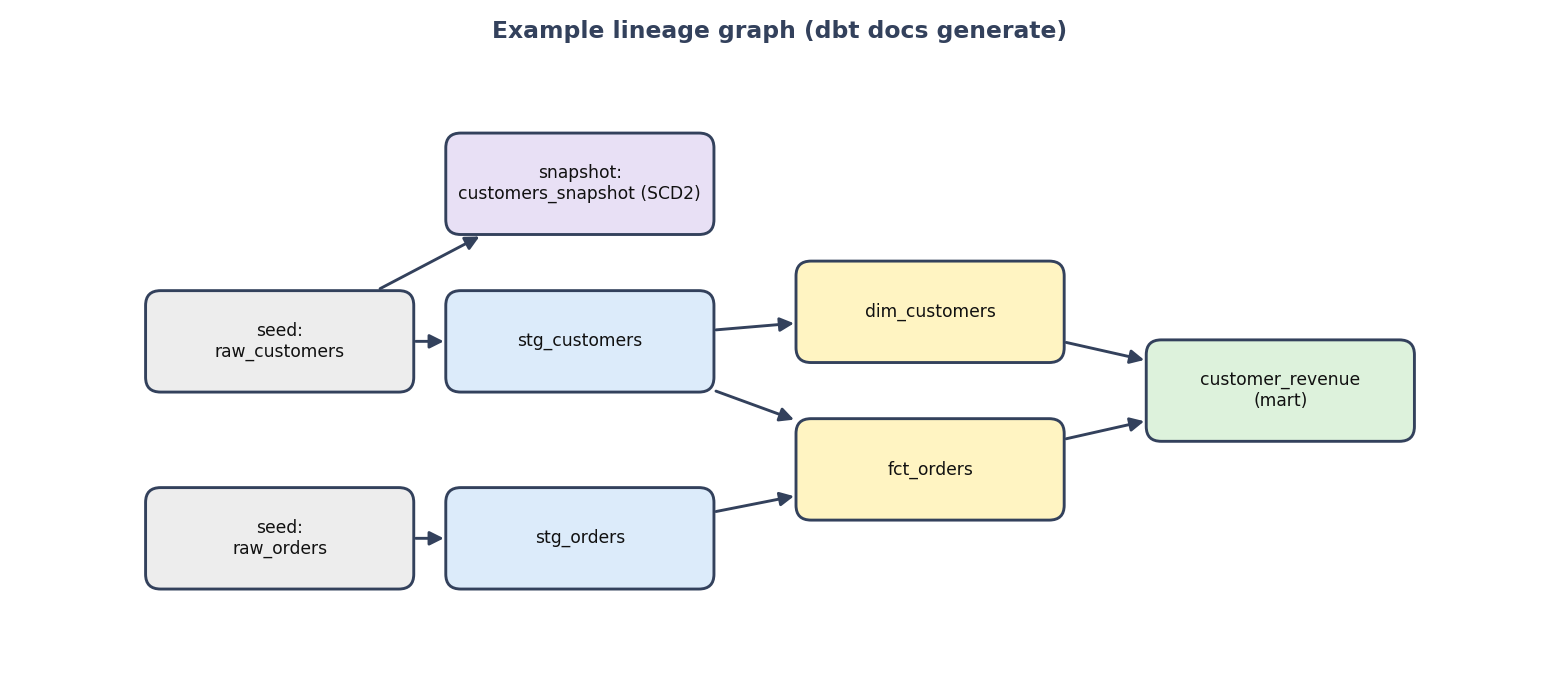

*The lineage graph you will see after `dbt docs generate`.*

In [ ]:
write(f"{P}/models/marts/fct_orders.sql", '''
    select
        o.order_id,
        o.customer_id,
        o.order_date,
        o.status,
        o.amount,
        case when o.status = 'completed' then o.amount else 0 end as recognized_revenue
    from {{ ref('stg_orders') }} o
''')

write(f"{P}/models/marts/dim_customers.sql", '''
    select * from {{ ref('stg_customers') }}
''')

write(f"{P}/models/marts/customer_revenue.sql", '''
    select
        c.customer_id,
        c.customer_name,
        c.tier,
        count(f.order_id)                 as orders,
        coalesce(sum(f.recognized_revenue), 0) as lifetime_revenue,
        min(f.order_date)                 as first_order_date
    from {{ ref('dim_customers') }} c
    left join {{ ref('fct_orders') }} f using (customer_id)
    group by 1, 2, 3
''')
sh("dbt run --profiles-dir .", cwd=P)
q("select * from main.customer_revenue order by lifetime_revenue desc")

## 2.3 Tests
Tests are assertions that must hold. dbt ships four **generic tests**: `unique`, `not_null`, `accepted_values`, `relationships`. A test passes when it returns **zero** failing rows.

In [ ]:
write(f"{P}/models/marts/_marts.yml", '''
    version: 2
    models:
      - name: fct_orders
        description: "One row per order."
        columns:
          - name: order_id
            description: "Primary key."
            tests: [unique, not_null]
          - name: customer_id
            tests:
              - not_null
              - relationships:
                  arguments: {to: "ref('dim_customers')", field: customer_id}
          - name: status
            tests:
              - accepted_values:
                  arguments:
                    values: ['completed', 'returned', 'pending']
      - name: dim_customers
        columns:
          - name: customer_id
            tests: [unique, not_null]
''')
sh("dbt test --profiles-dir .", cwd=P)

## 2.4 Materializations
How dbt builds a model is one line of config. Pick based on size and freshness needs.

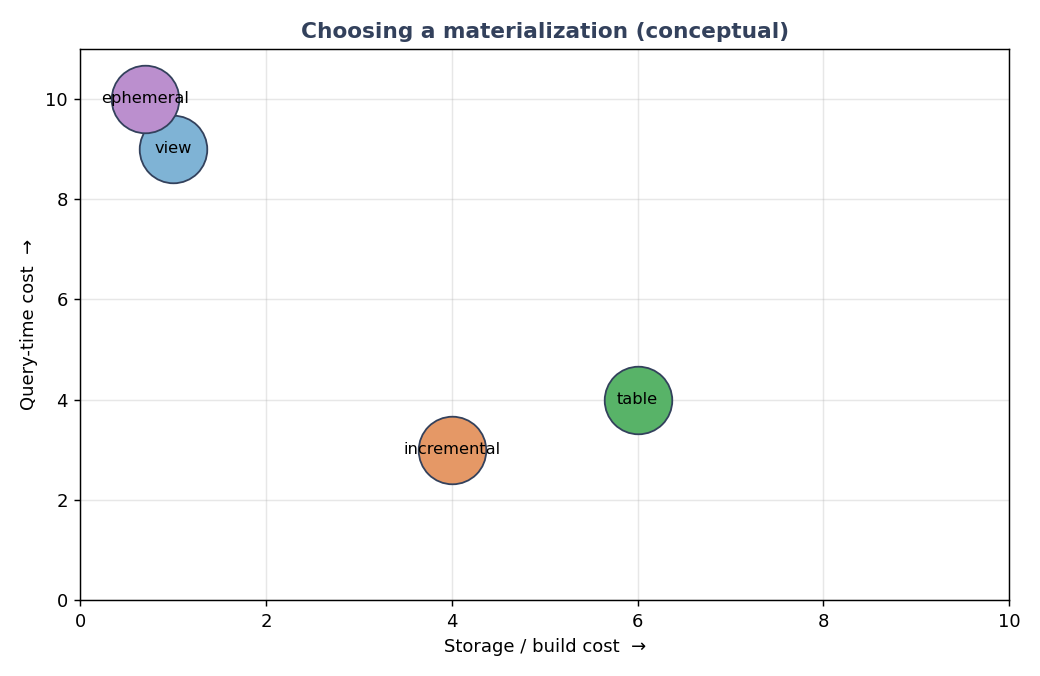

| Materialization | What it creates | Use when |
|---|---|---|
| `view` | a view (no data stored) | light transformations, staging |
| `table` | full rebuild every run | marts that are queried often, small/medium data |
| `incremental` | only new/changed rows are processed | large, append-heavy tables |
| `ephemeral` | inlined CTE, nothing created | tiny reusable logic |

## 2.5 Documentation
`dbt docs generate` builds a static site with the DAG, column descriptions and tests. `dbt docs serve` opens it in the browser.

In [ ]:
sh("dbt docs generate --profiles-dir .", cwd=P)
print(os.listdir(f"{P}/target")[:8])

### ✅ Intermediate exercises
1. Add a `not_null` test on `fct_orders.amount`, then break it on purpose and watch the test fail.
2. Add a `description` to every column of `customer_revenue`.
3. Build one model with `{{ config(materialized='ephemeral') }}` and see how its SQL is inlined (`target/compiled/`).

---
# 🔴 Level 3 - Advanced

## 3.1 Incremental models
For big tables you do not want to rebuild everything. An incremental model builds fully the first time, then only processes **new** rows. `is_incremental()` is true only on later runs, and `{{ this }}` refers to the existing table.

In [ ]:
write(f"{P}/models/marts/fct_orders_incremental.sql", '''
    {{ config(
        materialized='incremental',
        unique_key='order_id',
        incremental_strategy='delete+insert'
    ) }}

    select order_id, customer_id, order_date, status, amount
    from {{ ref('stg_orders') }}

    {% if is_incremental() %}
      -- only rows newer than what we already have
      where order_date > (select max(order_date) from {{ this }})
    {% endif %}
''')
sh("dbt run --select fct_orders_incremental --profiles-dir .", cwd=P)
print("--- add new order to the raw data and run again ---")
with open(f"{P}/seeds/raw_orders.csv", "a") as f:
    f.write("107,3,2026-03-01,completed,150.00\n")
sh("dbt seed --profiles-dir . && dbt run --select stg_orders fct_orders_incremental --profiles-dir .", cwd=P)
print(q("select count(*) as n_rows, max(order_date) as latest from main.fct_orders_incremental"))

> **Tip:** `dbt run --full-refresh` rebuilds an incremental model from scratch (use it after a logic change).

## 3.2 Snapshots = SCD Type 2 history
Source systems overwrite data (a customer moves city). A **snapshot** records every version with `dbt_valid_from` / `dbt_valid_to`, so you can answer "what did we know on 1 March?".

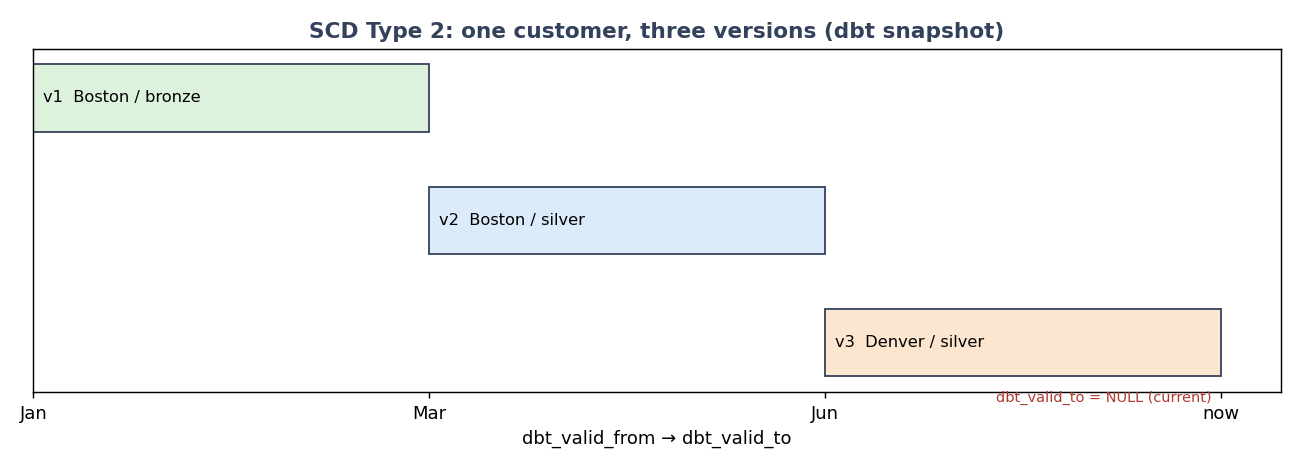

In [ ]:
write(f"{P}/snapshots/customers_snapshot.sql", '''
    {% snapshot customers_snapshot %}
    {{ config(
        target_schema='snapshots',
        unique_key='customer_id',
        strategy='check',
        check_cols=['city', 'tier']
    ) }}
    select * from {{ ref('raw_customers') }}
    {% endsnapshot %}
''')
sh("dbt snapshot --profiles-dir .", cwd=P)

In [ ]:
print("--- Ben moves to Denver and upgrades to gold ---")
csv = pathlib.Path(f"{P}/seeds/raw_customers.csv").read_text().replace("2,Ben,Austin,silver", "2,Ben,Denver,gold")
pathlib.Path(f"{P}/seeds/raw_customers.csv").write_text(csv)
sh("dbt seed --profiles-dir . && dbt snapshot --profiles-dir .", cwd=P)

q('''
    select customer_id, name, city, tier, dbt_valid_from, dbt_valid_to
    from snapshots.customers_snapshot
    order by customer_id, dbt_valid_from
''')

## 3.3 Jinja and macros
dbt SQL is templated with **Jinja**: loops, conditionals and reusable **macros** remove copy-paste.

In [ ]:
write(f"{P}/macros/cents_to_dollars.sql", '''
    {% macro round_money(column_name, precision=2) %}
        round(cast({{ column_name }} as decimal(18, {{ precision }})), {{ precision }})
    {% endmacro %}
''')

write(f"{P}/models/marts/revenue_by_status.sql", '''
    {% set statuses = ['completed', 'returned', 'pending'] %}
    select
        customer_id,
        {% for s in statuses %}
        {{ round_money("sum(case when status = '" ~ s ~ "' then amount else 0 end)") }} as {{ s }}_amount
        {{ "," if not loop.last }}
        {% endfor %}
    from {{ ref('fct_orders') }}
    group by customer_id
''')
sh("dbt run --select revenue_by_status --profiles-dir .", cwd=P)
print(q("select * from main.revenue_by_status order by 1"))

Peek at the **compiled SQL** that Jinja produced; this is the first place to look when debugging:

In [ ]:
print(pathlib.Path(f"{P}/target/compiled/shop_dbt/models/marts/revenue_by_status.sql").read_text())

## 3.4 Custom tests
A **singular test** is a SQL file that returns the rows that *violate* a rule. A **generic test** is a reusable macro.

In [ ]:
write(f"{P}/tests/assert_no_negative_amounts.sql", '''
    -- returns failing rows; zero rows = pass
    select * from {{ ref('fct_orders') }} where amount < 0
''')

write(f"{P}/macros/test_positive_value.sql", '''
    {% test positive_value(model, column_name) %}
    select * from {{ model }} where {{ column_name }} <= 0
    {% endtest %}
''')

write(f"{P}/models/marts/_marts_extra.yml", '''
    version: 2
    models:
      - name: customer_revenue
        columns:
          - name: orders
            tests: [not_null]
''')
sh("dbt test --profiles-dir .", cwd=P)

## 3.5 `dbt build`, selectors and state
`dbt build` = seed + run + snapshot + test **in DAG order**, and skips downstream models if an upstream test fails. Selectors let you run exactly what you need.

| Command | Meaning |
|---|---|
| `dbt build` | everything, in dependency order |
| `--select stg_orders+` | the model and everything **downstream** |
| `--select +fct_orders` | the model and everything **upstream** |
| `--select tag:daily` | models with a tag |
| `--select state:modified+ --state prod_artifacts/` | only changed models (CI) |
| `--exclude marts.*` | skip a folder |

In [ ]:
sh("dbt build --select +customer_revenue --profiles-dir .", cwd=P)

## 3.6 Environments, CI and production habits
- **Targets** in `profiles.yml` (`dev`, `ci`, `prod`) select the schema/warehouse: `dbt build --target prod`.
- **CI**: on every pull request run `dbt build --select state:modified+ --defer --state prod_artifacts/` so you only test what changed.
- **Slim deploys** + **freshness**: `dbt source freshness` alerts you when raw data stops arriving.
- **Contracts & versions** (dbt 1.5+): enforce column names and types on public models with `contract: {enforced: true}`.
- **Packages**: `dbt_utils` and `dbt_expectations` add dozens of ready-made macros and tests (`packages.yml` → `dbt deps`).
- **Style**: one model = one purpose, CTEs not sub-selects, snake_case, `stg_`, `int_`, `fct_`, `dim_` prefixes.

## 3.7 Orchestrating dbt with Airflow
dbt does not schedule itself. In production, Airflow (notebook 3) runs `dbt build` after your Spark job finishes:
```python
BashOperator(task_id="dbt_build", bash_command="cd /opt/shop_dbt && dbt build --profiles-dir .")
```
For per-model tasks in the Airflow UI, look at the open-source **Astronomer Cosmos** package.

### 🏁 Final challenge
Add a `dim_customers_history` model that exposes `customers_snapshot` as a clean SCD2 dimension (`valid_from`, `valid_to`, `is_current`), then write a test that each customer has exactly **one** current row.